In [1]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset uploaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving crop_yield.csv to crop_yield.csv
Dataset uploaded successfully!
Dataset shape: (19689, 10)

First 5 rows:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909



Column names:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


In [2]:

# 1. Dataset information
print("Dataset Information:")
df.info()

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 4. Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 5. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# 6. Check target column
print("\nYield Column:")
print(df["Yield"].head())

print("\nYield Data Type:", df["Yield"].dtype)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB

Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Total Missing V

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Crop,19689,55,Rice,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop_Year,19689.0,NaN,NaN,NaN,2009.127584,6.498099,1997.0,2004.0,2010.0,2015.0,2020.0
Season,19689,6,Kharif,8232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,19689,30,Karnataka,1432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,19689.0,NaN,NaN,NaN,179926.570308,732828.675888,0.5,1390.0,9317.0,75112.0,50808100.0
Production,19689.0,NaN,NaN,NaN,16435941.273097,263056839.812567,0.0,1393.0,13804.0,122718.0,6326000000.0
Annual_Rainfall,19689.0,NaN,NaN,NaN,1437.755177,816.909589,301.3,940.7,1247.6,1643.7,6552.7
Fertilizer,19689.0,NaN,NaN,NaN,24103312.448806,94946004.482527,54.17,188014.62,1234957.44,10003847.2,4835406877.0
Pesticide,19689.0,NaN,NaN,NaN,48848.353392,213287.35486,0.09,356.7,2421.9,20041.7,15750511.0
Yield,19689.0,NaN,NaN,NaN,79.954009,878.306193,0.0,0.6,1.03,2.388889,21105.0



Yield Column:
0       0.796087
1       0.710435
2       0.238333
3    5238.051739
4       0.420909
Name: Yield, dtype: float64

Yield Data Type: float64


In [3]:

# Step 3: Data Cleaning

# Keep a backup of the original dataset
df_original = df.copy()

# 1. Remove duplicate rows
df = df.drop_duplicates().copy()

# 2. Remove extra spaces from column names
df.columns = df.columns.str.strip()

# 3. Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# 4. Convert Yield into numeric format
df["Yield"] = pd.to_numeric(df["Yield"], errors="coerce")

# 5. Check missing values after cleaning
print("Dataset shape after removing duplicates:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows remaining:", df.duplicated().sum())

print("\nYield data type:", df["Yield"].dtype)


Dataset shape after removing duplicates: (19689, 10)

Missing values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Duplicate rows remaining: 0

Yield data type: float64


In [4]:

# Remove rows where Yield is missing
df = df.dropna(subset=["Yield"]).copy()

# Fill missing numerical values with median
num_cols = df.select_dtypes(include="number").columns.drop("Yield")

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Fill missing categorical values with mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())
print("Final dataset shape:", df.shape)


Remaining missing values: 0
Final dataset shape: (19689, 10)


In [5]:

print(df["Yield"].describe())

print("\nSmallest 5 yield values:")
print(df["Yield"].nsmallest(5))

print("\nLargest 5 yield values:")
print(df["Yield"].nlargest(5))

print("\nZero or negative yields:", (df["Yield"] <= 0).sum())


count    19689.000000
mean        79.954009
std        878.306193
min          0.000000
25%          0.600000
50%          1.030000
75%          2.388889
max      21105.000000
Name: Yield, dtype: float64

Smallest 5 yield values:
92      0.0
125     0.0
1058    0.0
1134    0.0
1135    0.0
Name: Yield, dtype: float64

Largest 5 yield values:
13962    21105.00000
5771     16935.05846
13406    16254.00000
5425     15636.63231
3610     14794.63000
Name: Yield, dtype: float64

Zero or negative yields: 112


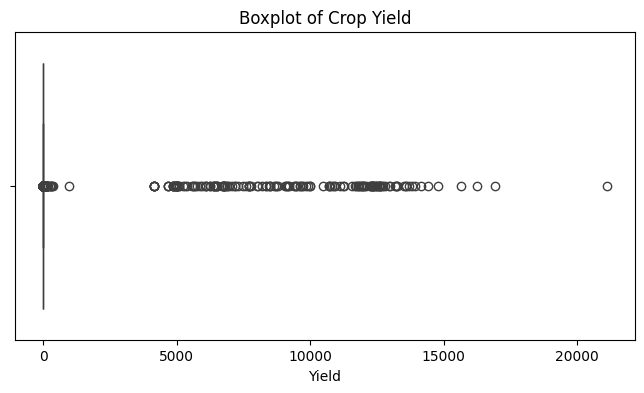

99th percentile: 104.27338669599955
Values above 99th percentile: 197


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Yield"])
plt.title("Boxplot of Crop Yield")
plt.show()

print("99th percentile:", df["Yield"].quantile(0.99))
print("Values above 99th percentile:",
      (df["Yield"] > df["Yield"].quantile(0.99)).sum())


In [10]:

# Check rows where Yield is zero
zero_yield = df[df["Yield"] == 0]

print("Zero-yield rows:", len(zero_yield))
display(zero_yield.head(10))

# Check crops and production for these rows
print("\nProduction values for zero-yield rows:")
print(zero_yield[["Crop", "State", "Area", "Production", "Yield"]].head(10))


Zero-yield rows: 112


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
92,Cardamom,1997,Whole Year,West Bengal,2674.0,7,1852.9,254484.58,828.94,0.0
125,Sunflower,1997,Whole Year,West Bengal,278.0,1,1852.9,26457.26,86.18,0.0
1058,Soyabean,2002,Kharif,Andhra Pradesh,41284.0,0,648.1,3908356.28,10321.00,0.0
1134,other oilseeds,2002,Whole Year,Kerala,2253.0,0,2511.2,213291.51,563.25,0.0
1135,Arecanut,2002,Whole Year,Tamil Nadu,4956.0,0,315.9,469184.52,1239.00,0.0
1273,other oilseeds,2003,Rabi,Andhra Pradesh,14609.0,0,826.0,1445998.82,3506.16,0.0
1441,Arecanut,2003,Whole Year,Tamil Nadu,5219.0,0,345.6,516576.62,1252.56,0.0
1651,Niger seed,2004,Kharif,Tamil Nadu,1239.0,0,1034.0,134233.26,260.19,0.0
1678,Garlic,2005,Whole Year,Andhra Pradesh,800.0,0,1075.5,95936.00,168.00,0.0
1883,Maize,2005,Kharif,Tamil Nadu,202830.0,0,1364.1,24323373.60,42594.30,0.0



Production values for zero-yield rows:
                Crop           State      Area  Production  Yield
92          Cardamom     West Bengal    2674.0           7    0.0
125        Sunflower     West Bengal     278.0           1    0.0
1058        Soyabean  Andhra Pradesh   41284.0           0    0.0
1134  other oilseeds          Kerala    2253.0           0    0.0
1135        Arecanut      Tamil Nadu    4956.0           0    0.0
1273  other oilseeds  Andhra Pradesh   14609.0           0    0.0
1441        Arecanut      Tamil Nadu    5219.0           0    0.0
1651      Niger seed      Tamil Nadu    1239.0           0    0.0
1678          Garlic  Andhra Pradesh     800.0           0    0.0
1883           Maize      Tamil Nadu  202830.0           0    0.0


In [11]:

# Check rows where Production is zero
print("Production = 0:", (df["Production"] == 0).sum())

# Check rows where Production > 0 but Yield = 0
check = df[(df["Production"] > 0) & (df["Yield"] == 0)]

print("Production > 0 but Yield = 0:", len(check))
display(check[["Crop", "State", "Area", "Production", "Yield"]].head(10))

# Check high-yield rows
print("\nHighest yield rows:")
display(df.nlargest(10, "Yield")[["Crop", "State", "Area", "Production", "Yield"]])


Production = 0: 112
Production > 0 but Yield = 0: 4


,Crop,State,Area,Production,Yield
92,Cardamom,West Bengal,2674.0,7,0.0
125,Sunflower,West Bengal,278.0,1,0.0
5371,Cotton(lint),Tamil Nadu,138290.0,337,0.0
5372,Cotton(lint),Tamil Nadu,43341.0,101,0.0



Highest yield rows:


,Crop,State,Area,Production,Yield
13962,Coconut,Telangana,439.0,9265095,21105.00000
5771,Coconut,Andhra Pradesh,104027.0,1912224000,16935.05846
13406,Coconut,Telangana,428.0,6956712,16254.00000
5425,Coconut,Andhra Pradesh,104530.0,1571100000,15636.63231
3610,Coconut,Andhra Pradesh,99825.0,1670659000,14794.63000
18015,Coconut,Puducherry,1564.0,20297000,14410.51667
3052,Coconut,Tamil Nadu,400466.0,5547100000,14134.65935
4742,Coconut,Andhra Pradesh,102548.0,1415300000,13934.12250
2724,Coconut,Tamil Nadu,389429.0,5362000000,13834.07258
3836,Coconut,Andhra Pradesh,99066.0,1610007000,13712.57308


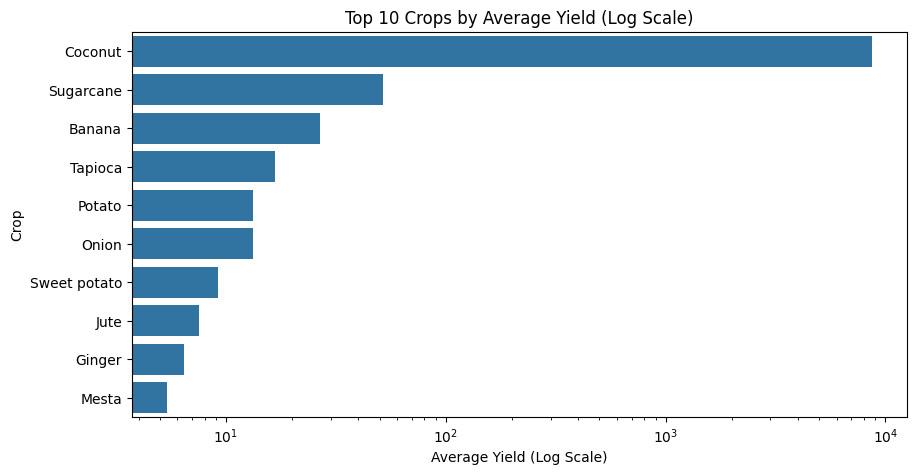

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
top_crops = df.groupby("Crop")["Yield"].mean().nlargest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_crops.values, y=top_crops.index)
plt.xscale("log")
plt.title("Top 10 Crops by Average Yield (Log Scale)")
plt.xlabel("Average Yield (Log Scale)")
plt.ylabel("Crop")
plt.show()


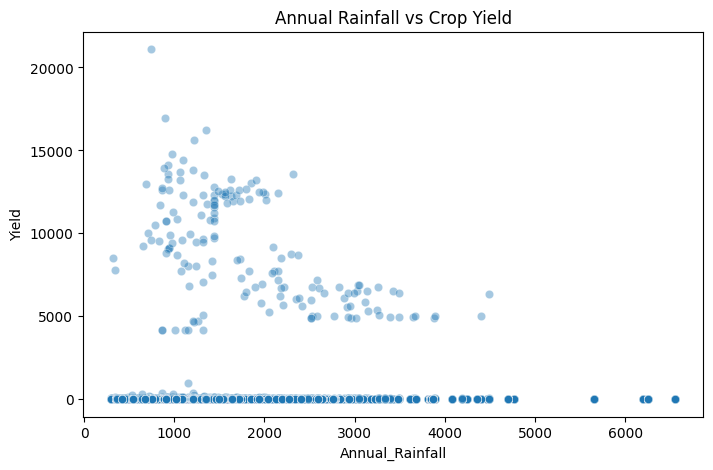

In [13]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Annual_Rainfall", y="Yield", alpha=0.4)
plt.title("Annual Rainfall vs Crop Yield")
plt.show()


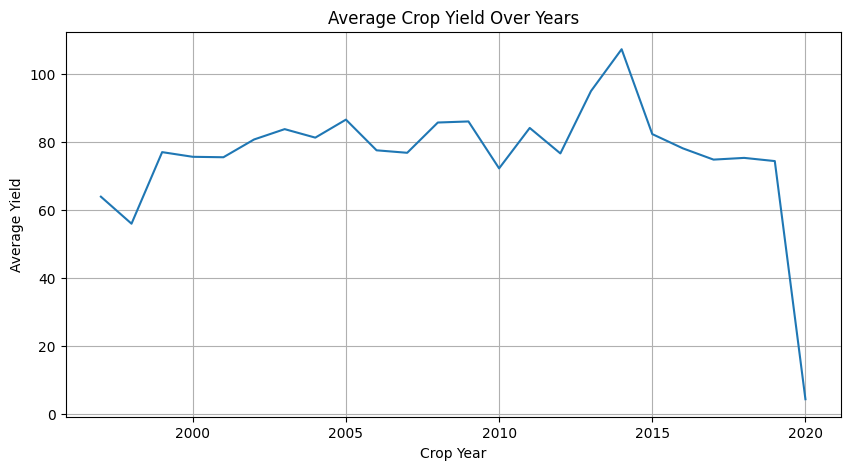

In [14]:

yearly_yield = df.groupby("Crop_Year")["Yield"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly_yield.index, y=yearly_yield.values)

plt.title("Average Crop Yield Over Years")
plt.xlabel("Crop Year")
plt.ylabel("Average Yield")
plt.grid(True)
plt.show()


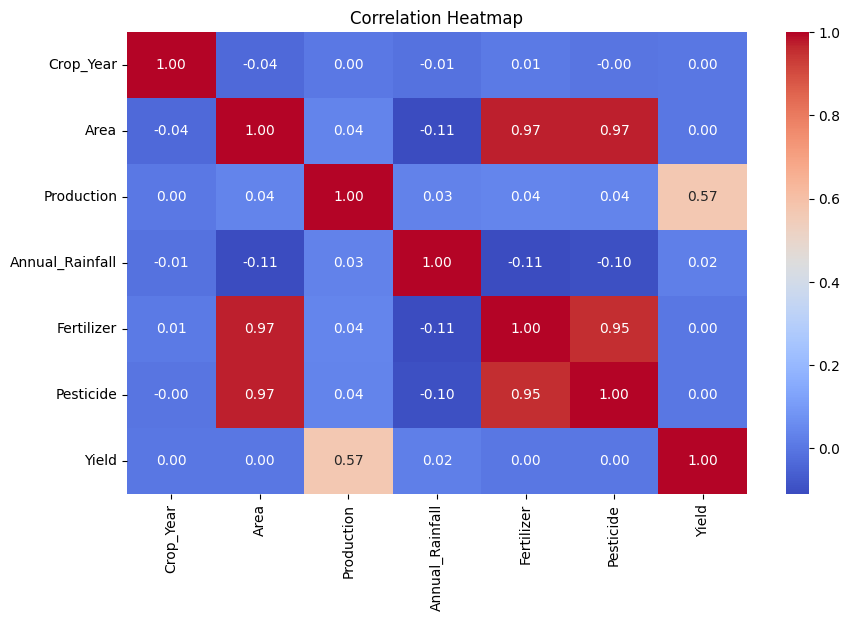

In [15]:

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


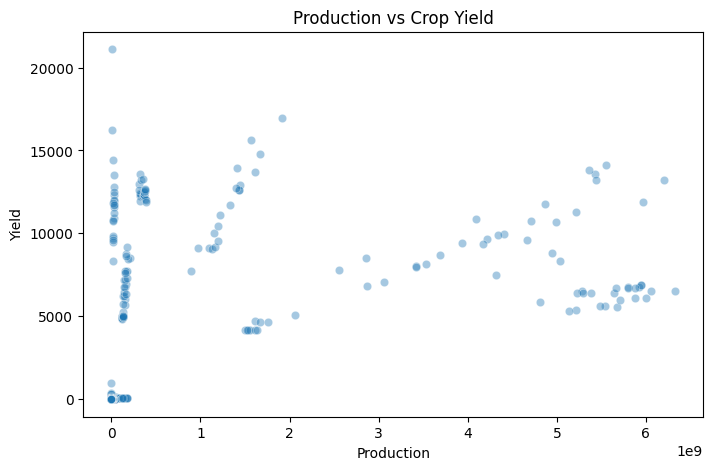

In [16]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Production",
    y="Yield",
    alpha=0.4
)

plt.title("Production vs Crop Yield")
plt.xlabel("Production")
plt.ylabel("Yield")
plt.show()


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

features = [
    "Crop", "Crop_Year", "Season", "State",
    "Area", "Annual_Rainfall", "Fertilizer", "Pesticide"
]

X = df[features]
y = df["Yield"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))


MAE: 63.88493040058693
RMSE: 389.6808093066365
R2 Score: 0.810479807867177


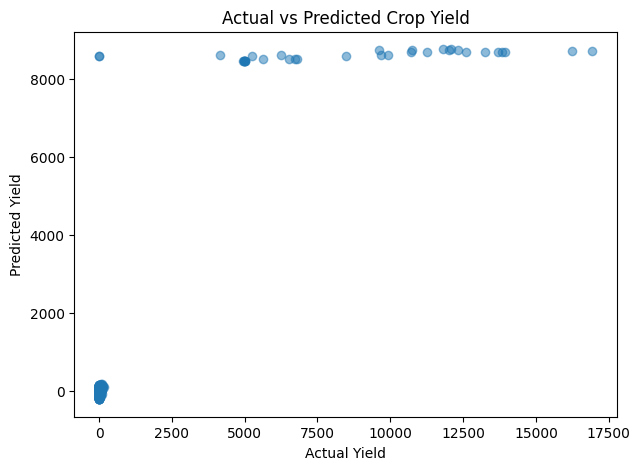

In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")

plt.show()


In [19]:

from sklearn.metrics import r2_score

r2 = r2_score(y_test, predictions)

print(f"R2 Score: {r2:.4f}")
print(f"R2 Percentage: {r2 * 100:.2f}%")


R2 Score: 0.8105
R2 Percentage: 81.05%


In [20]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Results")
print("MAE:", mean_absolute_error(y_test, rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("R2 Score:", r2_score(y_test, rf_predictions))


Random Forest Results
MAE: 9.44585212267479
RMSE: 126.04265868425797
R2 Score: 0.9801722898422972


In [21]:

from sklearn.metrics import r2_score

accuracy = r2_score(y_test, rf_predictions) * 100

print("Random Forest Model Performance:", round(accuracy, 2), "%")


Random Forest Model Performance: 98.02 %


In [22]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, predictions),
        r2_score(y_test, rf_predictions)
    ]
})

results["R2 (%)"] = (results["R2 Score"] * 100).round(2)

display(results.round(3))


,Model,MAE,RMSE,R2 Score,R2 (%)
0,Linear Regression,63.885,389.681,0.81,81.05
1,Random Forest,9.446,126.043,0.98,98.02


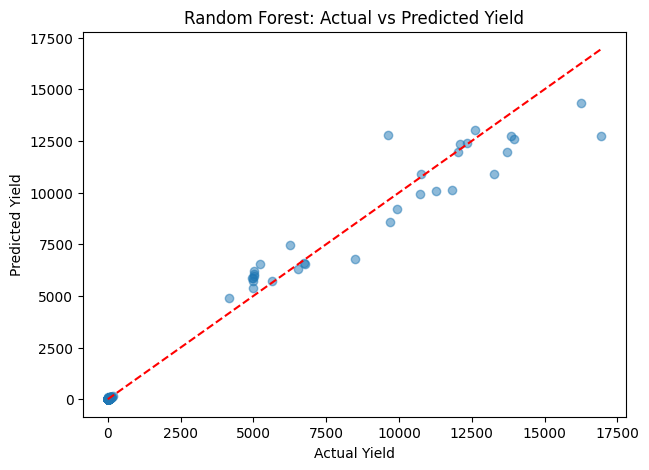

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, rf_predictions, alpha=0.5)

# Perfect prediction reference line
min_val = min(y_test.min(), rf_predictions.min())
max_val = max(y_test.max(), rf_predictions.max())

plt.plot([min_val, max_val], [min_val, max_val], "r--")

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Random Forest: Actual vs Predicted Yield")
plt.show()


In [24]:

import numpy as np
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

# Create yield categories using training data only
bins = np.quantile(y_train, [0, 1/3, 2/3, 1])
bins = np.unique(bins)

print("Yield category boundaries:", bins)

if len(bins) != 4:
    print("Warning: Yield values have tied quantiles; category boundaries need adjustment.")
else:
    y_train_class = np.digitize(y_train, bins[1:-1])
    y_test_class = np.digitize(y_test, bins[1:-1])

    class_names = {0: "Low", 1: "Medium", 2: "High"}

    clf = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ])

    clf.fit(X_train, y_train_class)
    class_predictions = clf.predict(X_test)

    print("\nClassification Accuracy:",
          round(accuracy_score(y_test_class, class_predictions) * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test_class,
        class_predictions,
        labels=[0, 1, 2],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    ))


Yield category boundaries: [0.00000000e+00 7.34000000e-01 1.72653846e+00 2.11050000e+04]

Classification Accuracy: 87.96 %

Classification Report:
              precision    recall  f1-score   support

         Low       0.88      0.88      0.88      1317
      Medium       0.83      0.84      0.83      1366
        High       0.94      0.93      0.93      1255

    accuracy                           0.88      3938
   macro avg       0.88      0.88      0.88      3938
weighted avg       0.88      0.88      0.88      3938



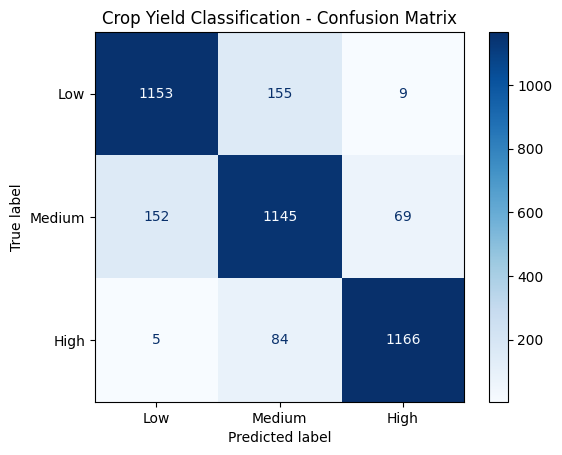

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    class_predictions,
    display_labels=["Low", "Medium", "High"],
    cmap="Blues"
)

plt.title("Crop Yield Classification - Confusion Matrix")
plt.show()

In [26]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(random_state=42))
])

dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

print("Decision Tree R2:", round(r2_score(y_test, dt_predictions), 3))
print("Decision Tree MAE:", round(mean_absolute_error(y_test, dt_predictions), 3))

print("Random Forest R2:", round(r2_score(y_test, rf_predictions), 3))
print("Random Forest MAE:", round(mean_absolute_error(y_test, rf_predictions), 3))

Decision Tree R2: 0.96
Decision Tree MAE: 11.799
Random Forest R2: 0.98
Random Forest MAE: 9.446


In [27]:
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

bagging_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_model.fit(X_train, y_train)
bagging_predictions = bagging_model.predict(X_test)

print("Bagging R2 Score:", round(r2_score(y_test, bagging_predictions), 3))
print("Bagging MAE:", round(mean_absolute_error(y_test, bagging_predictions), 3))

Bagging R2 Score: 0.98
Bagging MAE: 9.408


In [28]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    bagging_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("R2 Scores:", cv_scores.round(3))
print("Mean R2 Score:", round(cv_scores.mean(), 3))

R2 Scores: [0.829 0.96  0.979 0.984 0.98 ]
Mean R2 Score: 0.946


In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

tuning_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        random_state=42,
        n_jobs=1
    ))
])

params = {
    "regressor__n_estimators": [10, 30, 50],
    "regressor__estimator__max_depth": [10, 20, None],
    "regressor__max_samples": [0.7, 1.0]
}

grid = GridSearchCV(
    tuning_model, params, cv=3,
    scoring="r2", n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 3))

Best Parameters: {'regressor__estimator__max_depth': 20, 'regressor__max_samples': 1.0, 'regressor__n_estimators': 10}
Best CV R2: 0.941


In [30]:
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Bagging"],
    "R2 Score": [
        r2_score(y_test, predictions),
        r2_score(y_test, rf_predictions),
        r2_score(y_test, bagging_predictions)
    ],
    "MAE": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, rf_predictions),
        mean_absolute_error(y_test, bagging_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions)),
        np.sqrt(mean_squared_error(y_test, bagging_predictions))
    ]
})

display(results.round(3))

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.81,63.885,389.681
1,Random Forest,0.98,9.446,126.043
2,Bagging,0.98,9.408,127.958


In [31]:
import joblib

joblib.dump(bagging_model, "crop_yield_regression.pkl")
joblib.dump(clf, "crop_yield_classifier.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [32]:
# Show actual records with the lowest yield
low_records = df[df["Yield"] > 0].nsmallest(10, "Yield")

display(low_records[
    ["Crop", "Crop_Year", "Season", "State",
     "Area", "Annual_Rainfall", "Fertilizer",
     "Pesticide", "Yield"]
])

,Crop,Crop_Year,Season,State,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
11086,Jowar,2009,Kharif,Haryana,77671.0,393.0,12102695.22,13204.07,0.003571
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,1356.2,26242746.82,85481.26,0.016667
4934,Cowpea(Lobia),2016,Rabi,Karnataka,4191.0,1147.2,642270.75,1466.85,0.017647
6450,Moth,1998,Kharif,Haryana,2189.0,687.6,216273.20,634.81,0.028571
8506,Moth,2003,Kharif,Haryana,10365.0,592.3,1025927.70,2487.60,0.031429
3519,Cardamom,2011,Whole Year,Kerala,8510.0,3035.1,1425595.20,2808.30,0.038750
8020,Sannhamp,2002,Whole Year,Haryana,516.0,353.9,48849.72,129.00,0.040000
8014,Moth,2002,Kharif,Haryana,20304.0,353.9,1922179.68,5076.00,0.042000
8025,Urad,2002,Kharif,Haryana,3475.0,353.9,328978.25,868.75,0.042857
8517,Urad,2003,Kharif,Haryana,2419.0,592.3,239432.62,580.56,0.042857


In [33]:
print(df.columns.tolist())
print(df.loc[11086, [
    "Crop", "Crop_Year", "Season", "State",
    "Area", "Annual_Rainfall", "Fertilizer",
    "Pesticide", "Yield"
]])

['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
Crop                     Jowar
Crop_Year                 2009
Season                  Kharif
State                  Haryana
Area                   77671.0
Annual_Rainfall          393.0
Fertilizer         12102695.22
Pesticide             13204.07
Yield                 0.003571
Name: 11086, dtype: object


In [34]:
!pip install -q gradio

In [36]:
import gradio as gr

features = ["Crop", "Crop_Year", "Season", "State",
            "Area", "Annual_Rainfall", "Fertilizer", "Pesticide"]
labels = ["Low", "Medium", "High"]
colors = {"Low": "#e53935", "Medium": "#fb8c00", "High": "#2e7d32"}

def choices(col):
    return sorted(df[col].unique())

def predict(*values):
    data = pd.DataFrame([values], columns=features)
    value = bagging_model.predict(data)[0]
    level = labels[np.digitize(value, bins[1:-1])]
    return f"""
    <div class="result" style="border-color:{colors[level]}">
        <p>Predicted Yield</p>
        <h1>{value:,.2f}</h1>
        <span style="background:{colors[level]}">{level} Yield</span>
    </div>"""

style = """
<style>
  .hero {text-align:center; padding:28px; border-radius:18px; color:white;
         background:linear-gradient(120deg,#0f3d2a,#2e9e5b);}
  .hero h1 {margin:0; font-size:2.2em; color:white;}
  .hero p {margin:6px 0 0; opacity:.9; color:white;}
  .result {text-align:center; padding:26px; border-radius:18px;
           border:3px solid; background:rgba(46,158,91,.08);}
  .result p {margin:0; opacity:.7;}
  .result h1 {font-size:3em; margin:8px 0 14px;}
  .result span {color:white; padding:8px 22px; border-radius:999px; font-weight:600;}
  #predict-btn {background:#2e9e5b !important; color:white !important; font-weight:600;}
</style>
<div class="hero">
  <h1>🌾 CropSense AI</h1>
  <p>Smart crop yield prediction using machine learning</p>
</div>
"""

with gr.Blocks(title="CropSense AI") as demo:
    gr.HTML(style)

    with gr.Row():
        with gr.Column():
            gr.Markdown("### 🌱 Crop Details")
            crop = gr.Dropdown(choices("Crop"), value=choices("Crop")[0], label="Crop")
            season = gr.Dropdown(choices("Season"), value=choices("Season")[0], label="Season")
            state = gr.Dropdown(choices("State"), value=choices("State")[0], label="State")
            year = gr.Number(int(df["Crop_Year"].max()), precision=0, label="Crop Year")

        with gr.Column():
            gr.Markdown("### 🌦️ Farm Conditions")
            area = gr.Number(df["Area"].median(), label="Area")
            rain = gr.Number(df["Annual_Rainfall"].median(), label="Annual Rainfall")
            fert = gr.Number(df["Fertilizer"].median(), label="Fertilizer")
            pest = gr.Number(df["Pesticide"].median(), label="Pesticide")

    btn = gr.Button("🌿 Predict Yield", variant="primary", elem_id="predict-btn")
    output = gr.HTML()

    btn.click(predict,
              inputs=[crop, year, season, state, area, rain, fert, pest],
              outputs=output)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://19dde441de20787afe.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
